# Clasificador de imágenes: perros vs gatos (Asirra)

**Objetivo:** construir una red neuronal convolucional que distinga fotos de perros y gatos, superando
el 80 % de precisión que logró en 2007 el ataque con SVM al CAPTCHA de Asirra.

**Recorrido del notebook:**

1. Carga del conjunto de datos
2. Visualización y preparación de las imágenes (200×200)
3. Red neuronal base: EfficientNet-B0 desde cero, con la arquitectura del enunciado
4. Optimización: `ModelCheckpoint`, `EarlyStopping` y transfer learning
5. Guardado del modelo
6. Conclusiones

## 0. Configuración

**Decisiones técnicas:**

- **`tf-keras` en lugar de `keras`.** En Keras 3 se han eliminado `ImageDataGenerator` y `fit_generator`,
  que pide el enunciado. `tf-keras` es el paquete oficial que mantiene la API clásica de Keras 2 sobre TensorFlow 2.20.
- **200×200 en todo el flujo.** El enunciado pide redimensionar a 200×200, pero la arquitectura de ejemplo usa
  `input_shape=(224, 224, 3)`. EfficientNet-B0 acepta cualquier tamaño a partir de 32 px, así que usamos 200×200
  para que los datos y la red coincidan.
- **Sin `rescale=1/255`.** EfficientNet de Keras normaliza internamente y espera píxeles en [0, 255].
  Dividir por 255 en el generador estropearía la entrada.

In [1]:
import gc
import os
import random
import shutil
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # oculta avisos internos de TensorFlow (p. ej. "no hay GPU")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import tf_keras
from IPython.display import display
from PIL import Image
from tf_keras.applications import EfficientNetB0
from tf_keras.callbacks import EarlyStopping, ModelCheckpoint
from tf_keras.layers import Dense, GlobalAveragePooling2D
from tf_keras.models import Sequential, load_model
from tf_keras.preprocessing.image import ImageDataGenerator

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
SPLIT_DIR = PROJECT_ROOT / "data" / "interim" / "split"  # train/ y test/ con una subcarpeta por clase
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

IMG_SIZE = (200, 200)
BATCH_SIZE = 32
TEST_FRACTION = 0.2

print("TensorFlow:", tf.__version__, "· tf-keras:", tf_keras.__version__)
print("Raíz del proyecto:", PROJECT_ROOT)

TensorFlow: 2.20.0 · tf-keras: 2.20.1
Raíz del proyecto: /workspaces/aie-pt3-Machine-learning-nestornegrin


## 1. Carga del conjunto de datos

Buscamos las fotos etiquetadas en `data/raw/`. La etiqueta está en el nombre del archivo:
`cat.123.jpg` o `dog.456.jpg`.

In [2]:
labeled = sorted(
    p for p in RAW_DIR.rglob("*.jpg")
    if p.name.split(".")[0] in {"cat", "dog"} and "__MACOSX" not in p.parts
)
images = pd.DataFrame({"path": labeled})
images["label"] = images["path"].map(lambda p: p.name.split(".")[0])

print("Carpetas con fotos etiquetadas:", sorted({str(p.parent.relative_to(RAW_DIR)) for p in labeled}))
print("Fotos etiquetadas:", len(images))
images["label"].value_counts().to_frame("fotos")

Carpetas con fotos etiquetadas: ['dogs-vs-cats/train']
Fotos etiquetadas: 25000


,fotos
label,
cat,12500
dog,12500


Conjunto **equilibrado**: 12.500 perros y 12.500 gatos. Con clases equilibradas, la *accuracy* es una
métrica fiable y un clasificador al azar acertaría el 50 %.

## 2. Visualización de la información de entrada

### 2.1 Primeras nueve fotos de perros y de gatos

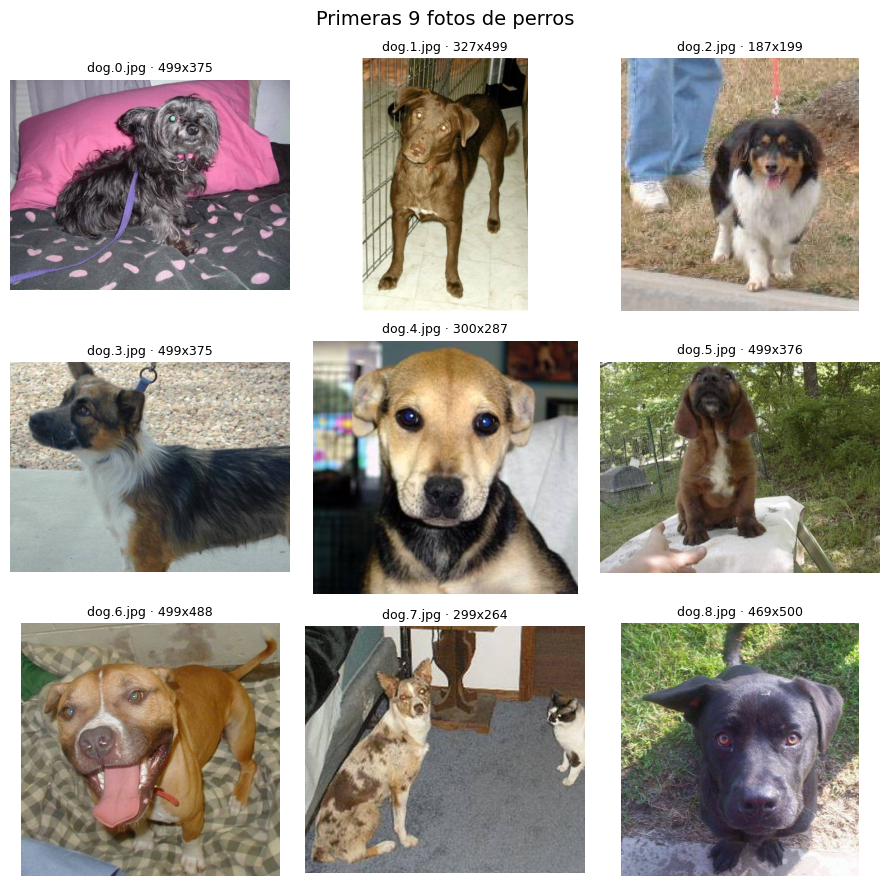

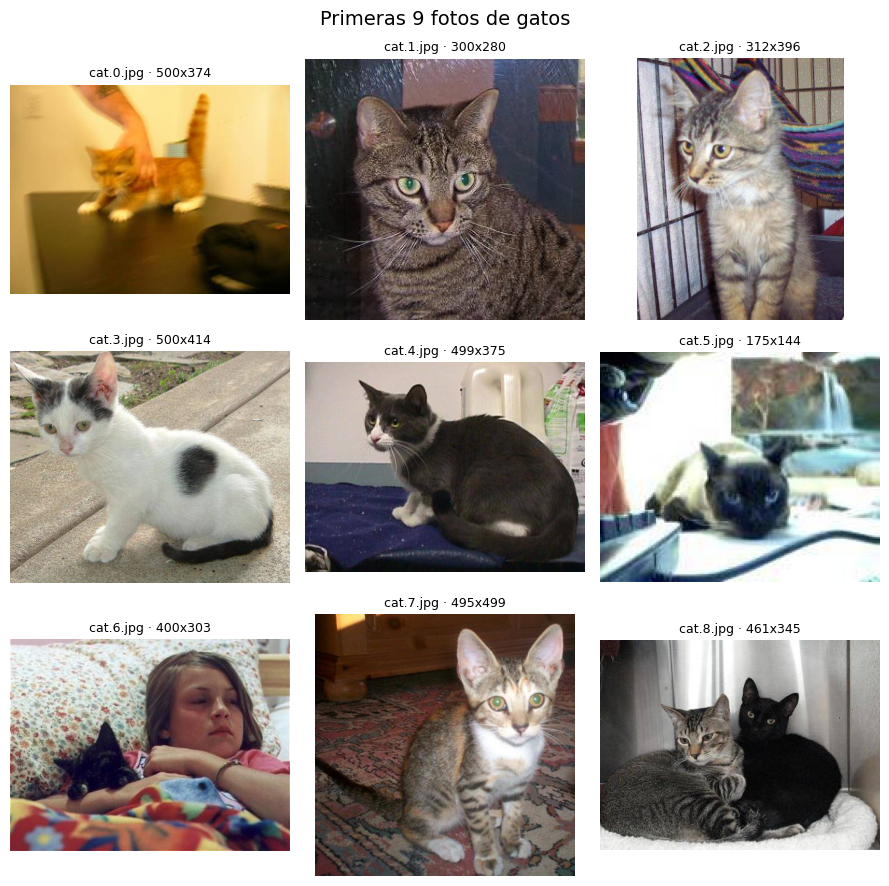

In [3]:
def show_grid(paths, title):
    """Muestra 9 imágenes en una cuadrícula 3x3 con su tamaño original."""
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for ax, path in zip(axes.ravel(), paths):
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"{path.name} · {img.size[0]}x{img.size[1]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


first_dogs = images[images["label"] == "dog"].sort_values("path", key=lambda s: s.map(lambda p: int(p.name.split(".")[1])))
first_cats = images[images["label"] == "cat"].sort_values("path", key=lambda s: s.map(lambda p: int(p.name.split(".")[1])))
show_grid(first_dogs["path"].head(9).tolist(), "Primeras 9 fotos de perros")
show_grid(first_cats["path"].head(9).tolist(), "Primeras 9 fotos de gatos")

### 2.2 Variedad de tamaños y formatos

Medimos una muestra aleatoria de 1.000 fotos para cuantificar la variedad.

In [4]:
sample = images.sample(min(1000, len(images)), random_state=SEED)
sizes = pd.DataFrame(
    [(*Image.open(p).size, Image.open(p).mode) for p in sample["path"]],
    columns=["ancho", "alto", "modo"],
)
display(sizes[["ancho", "alto"]].describe().round(0))
print("Modos de color:", sizes["modo"].value_counts().to_dict())
print("Tamaños distintos en la muestra:", sizes[["ancho", "alto"]].drop_duplicates().shape[0])

,ancho,alto
count,1000.0,1000.0
mean,402.0,357.0
std,107.0,98.0
min,66.0,50.0
25%,322.0,299.0
50%,431.0,374.0
75%,499.0,410.0
max,500.0,500.0


Modos de color: {'RGB': 1000}
Tamaños distintos en la muestra: 593


Las fotos tienen **cientos de tamaños distintos** y proporciones variadas, y casi todas son en color (RGB).
Antes de entrar en la red, todas se redimensionarán a **200×200 píxeles y 3 canales**.

### 2.3 ¿Cargar todo en memoria o progresivamente?

In [5]:
ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
in_memory_gb = len(images) * IMG_SIZE[0] * IMG_SIZE[1] * 3 * 4 / 1024**3  # float32

print(f"RAM de esta máquina: {ram_gb:.1f} GB")
print(f"Memoria necesaria para tener las {len(images)} fotos en float32: {in_memory_gb:.1f} GB")
print("Estrategia:", "cargar todo en memoria" if ram_gb > 12 else "carga progresiva con ImageDataGenerator.flow_from_directory()")

RAM de esta máquina: 7.8 GB
Memoria necesaria para tener las 25000 fotos en float32: 11.2 GB
Estrategia: carga progresiva con ImageDataGenerator.flow_from_directory()


Con menos de 12 GB de RAM aplicamos la **opción 2 del enunciado**: carga progresiva con
`ImageDataGenerator` y `flow_from_directory()`. Para ello las fotos deben estar organizadas así:

```
data/interim/split/
├── train/  ├── cats/  └── dogs/
└── test/   ├── cats/  └── dogs/
```

### 2.4 División train / test (80 / 20)

Separamos el 20 % de cada clase como test. Usamos **enlaces duros** (*hard links*): las fotos no se copian,
así que no ocupan espacio extra en disco. Si la división ya existe, no se rehace.

In [6]:
def build_split(images, split_dir, test_fraction, seed):
    """Crea split_dir/{train,test}/{cats,dogs}/ estratificado por clase."""
    expected = len(images)
    if split_dir.exists() and sum(1 for _ in split_dir.rglob("*.jpg")) == expected:
        print("La división ya existe; se reutiliza.")
        return

    shutil.rmtree(split_dir, ignore_errors=True)
    for label, group in images.groupby("label"):
        paths = group["path"].sample(frac=1, random_state=seed).tolist()
        n_test = int(len(paths) * test_fraction)
        for subset, subset_paths in (("test", paths[:n_test]), ("train", paths[n_test:])):
            target = split_dir / subset / f"{label}s"
            target.mkdir(parents=True, exist_ok=True)
            for src in subset_paths:
                dst = target / src.name
                try:
                    os.link(src, dst)  # sin duplicar datos en disco
                except OSError:
                    shutil.copy2(src, dst)


build_split(images, SPLIT_DIR, TEST_FRACTION, SEED)

split_counts = pd.DataFrame({
    subset: {cls: len(list((SPLIT_DIR / subset / cls).glob("*.jpg"))) for cls in ("cats", "dogs")}
    for subset in ("train", "test")
})
split_counts.loc["total"] = split_counts.sum()
split_counts

La división ya existe; se reutiliza.


,train,test
cats,10000,2500
dogs,10000,2500
total,20000,5000


### 2.5 Generadores `trdata` y `tsdata`

- **`trdata`** (entrenamiento) aplica un volteo horizontal aleatorio: un perro mirando a la izquierda sigue
  siendo un perro. Es una forma barata de dar más variedad al modelo.
- **`tsdata`** (test) no transforma nada y **no baraja** las fotos, para poder comparar cada predicción con su etiqueta real.

In [7]:
trdata = ImageDataGenerator(horizontal_flip=True)
tsdata = ImageDataGenerator()

train_data = trdata.flow_from_directory(
    SPLIT_DIR / "train", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True, seed=SEED,
)
test_data = tsdata.flow_from_directory(
    SPLIT_DIR / "test", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False,
)

CLASS_NAMES = {v: k for k, v in train_data.class_indices.items()}
print("Índice de clases:", train_data.class_indices)

batch_x, batch_y = next(train_data)
print("Forma de un lote de imágenes:", batch_x.shape, "· rango de píxeles:", batch_x.min(), "-", batch_x.max())
print("Forma de las etiquetas (one-hot):", batch_y.shape)

Found 20000 images belonging to 2 classes.


Found 5000 images belonging to 2 classes.


Índice de clases: {'cats': 0, 'dogs': 1}
Forma de un lote de imágenes: (32, 200, 200, 3) · rango de píxeles: 0.0 - 255.0
Forma de las etiquetas (one-hot): (32, 2)


Las imágenes ya llegan a la red como lotes de **32 × 200 × 200 × 3**, con etiquetas *one-hot*
(`[1, 0]` = gato, `[0, 1]` = perro), lo que encaja con la capa de salida `Dense(2, softmax)`.

## 3. Red neuronal base: EfficientNet-B0 desde cero

Usamos la arquitectura de prueba del enunciado tal cual: `weights=None`, es decir, la red empieza
con pesos aleatorios y tiene que aprenderlo todo con nuestras fotos.

**Memoria:** entrenar la red completa con lotes de 32 fotos de 200×200 necesita unos 3,6 GB de RAM solo para el
modelo. En un Codespace de 8 GB (compartidos con el editor) eso puede tumbar el kernel, así que el modelo base
usa **lotes de 16** (unos 2,3 GB).

**Limitación de hardware:** en un Codespace de 2 CPU, una época completa (20.000 fotos) con esta red
tarda unos 25 minutos (medido abajo: ~2,5 min por cada 1.920 fotos), y entrenar desde cero necesita decenas de épocas. Para **medir su rendimiento**
la entrenamos con una muestra: 2 épocas de 120 lotes de 16 (3.840 fotos vistas) y la evaluamos con 640 fotos de test.

In [8]:
def build_model(weights):
    """Arquitectura del enunciado. weights=None (desde cero) o 'imagenet' (transfer learning)."""
    model = Sequential()
    model.add(EfficientNetB0(include_top=False, weights=weights, input_shape=(*IMG_SIZE, 3)))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units=128, activation="relu"))
    model.add(Dense(units=2, activation="softmax"))
    return model


baseline = build_model(weights=None)
baseline.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 efficientnetb0 (Functional  (None, 7, 7, 1280)        4049571   


 )                                                               


...

 dense_1 (Dense)             (None, 2)                 258       


Total params: 4213797 (16.07 MB)


Trainable params: 4171774 (15.91 MB)


Non-trainable params: 42023 (164.16 KB)


_________________________________________________________________


In [9]:
BASELINE_BATCH = 16
BASELINE_STEPS = 120
BASELINE_EPOCHS = 2
EVAL_STEPS = 40

# Generadores propios con lotes más pequeños para no agotar la RAM
baseline_train = trdata.flow_from_directory(
    SPLIT_DIR / "train", target_size=IMG_SIZE, batch_size=BASELINE_BATCH,
    class_mode="categorical", shuffle=True, seed=SEED,
)
baseline_test = tsdata.flow_from_directory(
    SPLIT_DIR / "test", target_size=IMG_SIZE, batch_size=BASELINE_BATCH,
    class_mode="categorical", shuffle=True, seed=SEED,  # barajado: muestra con perros y gatos
)

start = time.perf_counter()
baseline_history = baseline.fit(
    baseline_train,
    steps_per_epoch=BASELINE_STEPS,
    epochs=BASELINE_EPOCHS,
    validation_data=baseline_test,
    validation_steps=EVAL_STEPS,
    verbose=2,
)
baseline_minutes = (time.perf_counter() - start) / 60

baseline_test.reset()
baseline_loss, baseline_acc = baseline.evaluate(baseline_test, steps=EVAL_STEPS, verbose=0)
print(f"\nEntrenamiento: {baseline_minutes:.1f} min")
print(f"Accuracy del modelo base en test ({EVAL_STEPS * BASELINE_BATCH} fotos): {baseline_acc:.1%}")

# Liberamos la memoria del modelo base antes de construir el siguiente
del baseline, baseline_train, baseline_test
tf_keras.backend.clear_session()
_ = gc.collect()

Found 20000 images belonging to 2 classes.


Found 5000 images belonging to 2 classes.


Epoch 1/2


120/120 - 165s - loss: 0.7665 - accuracy: 0.5349 - val_loss: 0.6929 - val_accuracy: 0.5156 - 165s/epoch - 1s/step


Epoch 2/2


120/120 - 148s - loss: 0.6858 - accuracy: 0.5891 - val_loss: 1.0965 - val_accuracy: 0.5125 - 148s/epoch - 1s/step



Entrenamiento: 5.2 min
Accuracy del modelo base en test (640 fotos): 48.4%


**Resultado: 48,4 %, exactamente el nivel del azar.** En entrenamiento llega al 58,9 %, pero en test no generaliza:
la pérdida de validación incluso empeora (0,69 → 1,10). Con pesos aleatorios, unos pocos miles de fotos no bastan
para que una red de 4 millones de parámetros aprenda a ver. Entrenarla hasta que funcione bien exigiría muchas
horas de CPU que no tenemos.

## 4. Optimización del modelo

Aplicamos dos mejoras:

1. **Transfer learning.** Misma arquitectura, pero EfficientNet-B0 empieza con los pesos aprendidos en
   **ImageNet**: 1,2 millones de fotos y 1.000 categorías, entre ellas muchas razas de perros y gatos.
   Congelamos la base convolucional y solo entrenamos las capas densas finales. Así la red ya "sabe ver"
   y solo aprende a decidir entre perro y gato.
2. **Callbacks**, como pide el enunciado:
   - `ModelCheckpoint` guarda el modelo cada vez que mejora la pérdida de validación.
   - `EarlyStopping` detiene el entrenamiento si deja de mejorar y recupera los mejores pesos.

> El enunciado menciona `fit_generator`. En Keras moderno es un alias obsoleto de `fit`, que acepta
> generadores directamente, así que pasamos los callbacks a `fit`.

In [10]:
model = build_model(weights="imagenet")
model.layers[0].trainable = False  # base EfficientNet congelada
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
print(f"Parámetros totales: {model.count_params():,} · entrenables: {int(trainable):,}")

    8192/16705208 [..............................] - ETA: 0s

   49152/16705208 [..............................] - ETA: 32s

   81920/16705208 [..............................] - ETA: 38s

  409600/16705208 [..............................] - ETA: 9s 

  606208/16705208 [>.............................] - ETA: 7s

...

12337152/16705208 [=====================>........] - ETA: 0s

14467072/16705208 [========================>.....] - ETA: 0s

16596992/16705208 [============================>.] - ETA: 0s

16705208/16705208 [==============================] - 1s 0us/step


Parámetros totales: 4,213,797 · entrenables: 164,226


In [11]:
CHECKPOINT_PATH = MODELS_DIR / "best_model.keras"

checkpoint = ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH), monitor="val_loss", save_best_only=True, verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_loss", patience=1, restore_best_weights=True, verbose=1,
)

TRAIN_STEPS = 300   # 9.600 fotos por época (aleatorias en cada época)
VAL_STEPS = 50      # 1.600 fotos de test para vigilar el entrenamiento
MAX_EPOCHS = 4

start = time.perf_counter()
history = model.fit(
    train_data,
    steps_per_epoch=TRAIN_STEPS,
    epochs=MAX_EPOCHS,
    validation_data=test_data,
    validation_steps=VAL_STEPS,
    callbacks=[checkpoint, early_stopping],
    verbose=2,
)
print(f"\nEntrenamiento optimizado: {(time.perf_counter() - start) / 60:.1f} min")

Epoch 1/4



Epoch 1: val_loss improved from inf to 0.02042, saving model to /workspaces/aie-pt3-Machine-learning-nestornegrin/models/best_model.keras


300/300 - 178s - loss: 0.0440 - accuracy: 0.9832 - val_loss: 0.0204 - val_accuracy: 0.9894 - 178s/epoch - 592ms/step


Epoch 2/4



Epoch 2: val_loss did not improve from 0.02042


300/300 - 171s - loss: 0.0283 - accuracy: 0.9899 - val_loss: 0.0270 - val_accuracy: 0.9906 - 171s/epoch - 570ms/step


Epoch 2: early stopping


Restoring model weights from the end of the best epoch: 1.



Entrenamiento optimizado: 5.8 min


,loss,accuracy,val_loss,val_accuracy
1,0.0440,0.9832,0.0204,0.9894
2,0.0283,0.9899,0.0270,0.9906


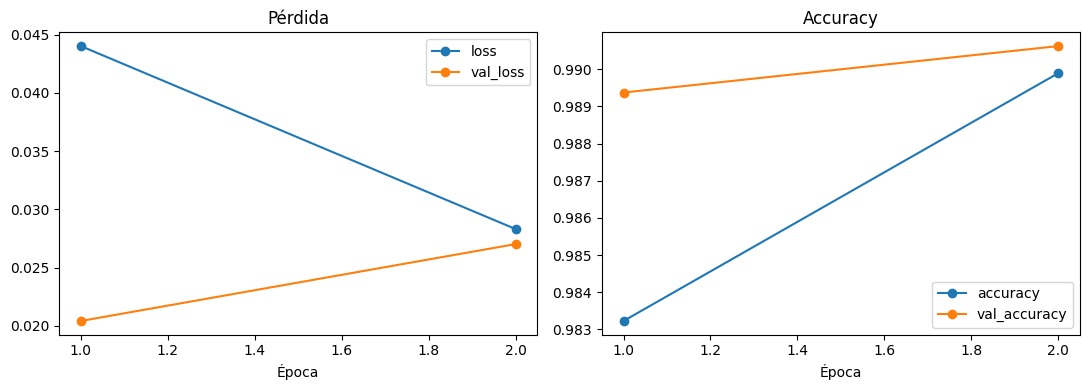

In [12]:
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
display(hist.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
hist[["loss", "val_loss"]].plot(ax=ax1, marker="o", title="Pérdida")
hist[["accuracy", "val_accuracy"]].plot(ax=ax2, marker="o", title="Accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("Época")
plt.tight_layout()
plt.show()

### 4.1 Cargar el mejor modelo y predecir sobre **todo** el conjunto de test

Cargamos el modelo que guardó `ModelCheckpoint` (el de menor pérdida de validación) y lo evaluamos con
las 5.000 fotos de test, que la red nunca ha usado para entrenar.

In [13]:
best_model = load_model(CHECKPOINT_PATH)

test_data.reset()
start = time.perf_counter()
probabilities = best_model.predict(test_data, verbose=0)
print(f"Predicción de {len(probabilities)} fotos en {(time.perf_counter() - start) / 60:.1f} min")

results = pd.DataFrame({
    "file": test_data.filenames,
    "real": [CLASS_NAMES[i] for i in test_data.classes],
    "predicho": [CLASS_NAMES[i] for i in probabilities.argmax(axis=1)],
    "confianza": probabilities.max(axis=1).round(4),
})
results["correcto"] = results["real"] == results["predicho"]

test_accuracy = results["correcto"].mean()
print(f"Accuracy en test: {test_accuracy:.2%}  ({results['correcto'].sum()} de {len(results)})")
print(f"Modelo base (sección 3): {baseline_acc:.1%}  ·  SVM de 2007: 80 %")

Predicción de 5000 fotos en 1.3 min
Accuracy en test: 98.94%  (4947 de 5000)
Modelo base (sección 3): 48.4%  ·  SVM de 2007: 80 %


In [14]:
confusion = pd.crosstab(results["real"], results["predicho"], rownames=["Real"], colnames=["Predicho"])
display(confusion)

metrics = pd.DataFrame({
    cls: {
        "precisión": (results.loc[results["predicho"] == cls, "correcto"]).mean(),
        "recall": (results.loc[results["real"] == cls, "correcto"]).mean(),
    }
    for cls in ("cats", "dogs")
}).T.round(4)
metrics

Predicho,cats,dogs
Real,,
cats,2482,18
dogs,35,2465


,precisión,recall
cats,0.9861,0.9928
dogs,0.9928,0.9860


### 4.2 ¿En qué fotos se equivoca?

Errores: 53


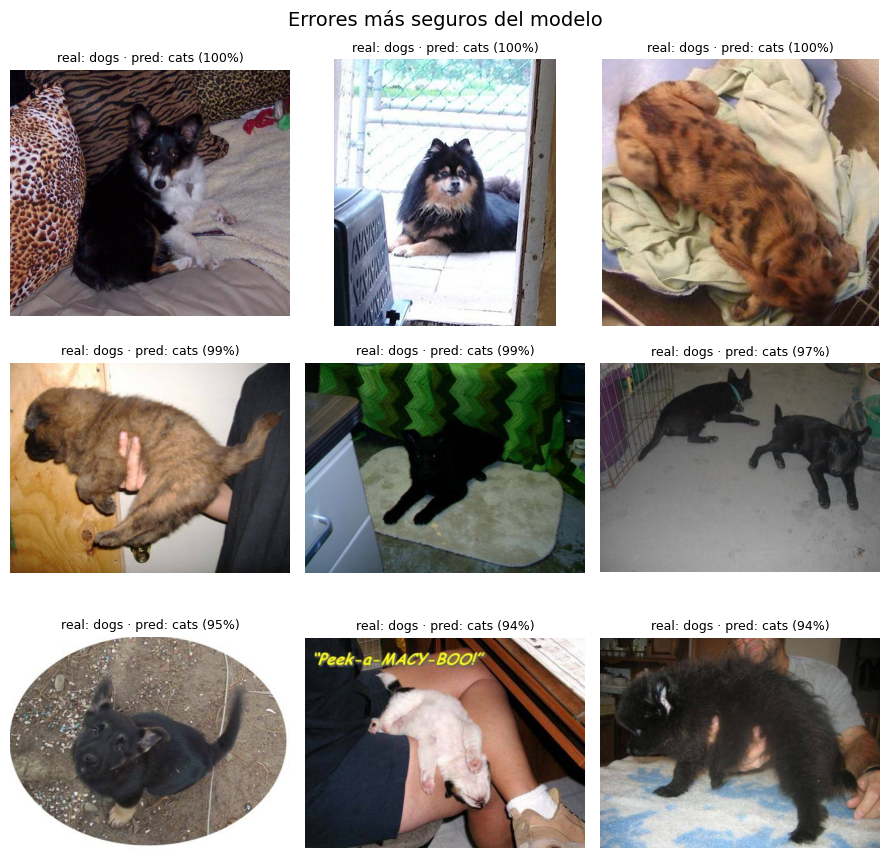

In [15]:
errors = results[~results["correcto"]].sort_values("confianza", ascending=False)
print(f"Errores: {len(errors)}")

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, (_, row) in zip(axes.ravel(), errors.head(9).iterrows()):
    ax.imshow(Image.open(SPLIT_DIR / "test" / row["file"]))
    ax.set_title(f"real: {row['real']} · pred: {row['predicho']} ({row['confianza']:.0%})", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(errors.head(9)):]:
    ax.axis("off")
fig.suptitle("Errores más seguros del modelo", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Guardar el modelo

Guardamos el mejor modelo en `models/` con un nombre descriptivo y eliminamos el checkpoint temporal.

In [16]:
FINAL_MODEL_PATH = MODELS_DIR / "dogs_vs_cats_efficientnetb0.keras"
best_model.save(FINAL_MODEL_PATH)
CHECKPOINT_PATH.unlink(missing_ok=True)

size_mb = FINAL_MODEL_PATH.stat().st_size / 1024**2
print(f"Modelo guardado en {FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)} ({size_mb:.1f} MB)")

# Comprobación: el archivo guardado se carga y predice igual que el modelo en memoria
reloaded = load_model(FINAL_MODEL_PATH)
test_data.reset()
check_x, _ = next(test_data)
print("Predicciones idénticas tras recargar:",
      np.allclose(reloaded.predict(check_x, verbose=0), best_model.predict(check_x, verbose=0), atol=1e-5))

Modelo guardado en models/dogs_vs_cats_efficientnetb0.keras (18.0 MB)


Predicciones idénticas tras recargar: True


## 6. Conclusiones

In [17]:
summary = pd.DataFrame({
    "Accuracy": [0.80, baseline_acc, test_accuracy],
    "Datos de evaluación": ["Paper 2007", f"{EVAL_STEPS * BASELINE_BATCH} fotos de test", f"{len(results)} fotos de test"],
}, index=["SVM (2007)", "EfficientNet-B0 desde cero (muestra)", "EfficientNet-B0 + ImageNet (optimizado)"])
summary["Accuracy"] = summary["Accuracy"].map("{:.1%}".format)
summary

,Accuracy,Datos de evaluación
SVM (2007),80.0%,Paper 2007
EfficientNet-B0 desde cero (muestra),48.4%,640 fotos de test
EfficientNet-B0 + ImageNet (optimizado),98.9%,5000 fotos de test


### Resultados

| Modelo | Accuracy en test | Tiempo de entrenamiento (2 CPU) |
|---|---|---|
| SVM del paper de 2007 | 80 % | — |
| EfficientNet-B0 desde cero (muestra) | 48,4 % | 5,2 min |
| **EfficientNet-B0 + ImageNet (optimizado)** | **98,94 %** (4.947 de 5.000) | **5,8 min** |

**1. El modelo optimizado acierta el 98,9 % de 5.000 fotos que nunca vio.** Supera ampliamente el 80 % del SVM que
"rompió" Asirra en 2007 y se acerca al 99,6 % de los humanos. Asirra ya no serviría como CAPTCHA.

**2. Es un modelo equilibrado.** Precisión y recall están entre el 98,6 % y el 99,3 % en ambas clases: no favorece a
perros ni a gatos.

**3. La clave fue el transfer learning, no más cómputo.** Con la misma arquitectura y el mismo hardware, pasar de
pesos aleatorios a pesos de ImageNet llevó el modelo del 48 % al 99 % en un tiempo similar. Solo entrenamos 164.226
de sus 4,2 millones de parámetros (las capas densas finales), porque la base ya sabía reconocer formas, texturas y animales.

**4. Los callbacks funcionaron como se esperaba.** El mejor resultado llegó en la **primera época**
(`val_loss` = 0,0204). En la segunda la pérdida de validación empeoró, así que `EarlyStopping` detuvo el
entrenamiento y recuperó los pesos de la época 1, que son los que guardó `ModelCheckpoint` y los que usamos para predecir.

**5. Los errores tienen un patrón claro.** De los 53 fallos, 35 son perros clasificados como gatos. En la cuadrícula
de la sección 4.2, los errores más seguros son **perros pequeños o cachorros, peludos, oscuros y con orejas
puntiagudas**, tumbados sobre mantas o sofás, o en posturas donde no se ve bien el hocico. Visualmente son los
casos que más se parecen a un gato.

### Siguientes pasos para mejorar

- **Fine-tuning:** descongelar los últimos bloques de EfficientNet y entrenarlos con un *learning rate* bajo.
  Es la mejora típica para pasar del 99 %, pero en CPU tarda bastante más.
- **Más aumento de datos** (giros, zoom, recortes) para los casos difíciles, como cachorros o animales de espaldas.
- **Revisar las etiquetas de los errores:** este dataset tiene algunas fotos mal etiquetadas, y parte de los
  53 "errores" podrían ser aciertos.